# Тема 1. Геометрическая вероятность на примере мишени

**Условие**

На лесной ярмарке енот бросает мягкий мячик в щит с нарисованным яблоком. Попадание засчитывается если центр мячика оказался внутри красного круга.

Пусть мячик с одинаковым шансом может попасть в любую точку выделенного прямоугольника. Посчитаем вероятность попадания в яблоко и проверим её на бросках в Python.

![Енот в жёлтой шапке держит мячик рядом с деревянным щитом. На щите нарисовано красное яблоко.](enot_i_mishen.png)

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## 1. Расчёт

$$P = \frac{\pi r^2}{\text{ширина} \cdot \text{высота}}.$$

In [2]:
# Левый верхний угол поля и его размеры.
x_shit, y_shit = 620, 180
shir, vys = 825, 570

# Центр яблока и радиус красного круга.
x0, y0, r = 1027, 450, 114

s_shit = shir * vys
s_krug = np.pi * r**2
p = s_krug / s_shit

print(f'Площадь поля: {s_shit} пикселей²')
print(f'Площадь круга: {s_krug:.1f} пикселей²')
print(f'Шанс попасть в яблоко: {p:.2%}')

Площадь поля: 470250 пикселей²
Площадь круга: 40828.1 пикселей²
Шанс попасть в яблоко: 8.68%


## 2. Первые 600 броска

In [3]:
sluch = np.random.default_rng(42)
n = 100_000

x = sluch.uniform(x_shit, x_shit + shir, n)
y = sluch.uniform(y_shit, y_shit + vys, n)
popal = (x - x0)**2 + (y - y0)**2 <= r**2

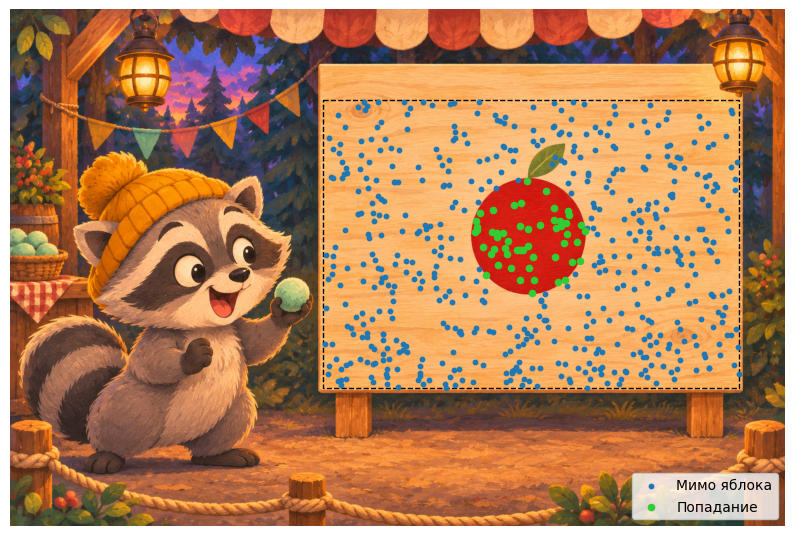

In [4]:
x_ris, y_ris = x[:600], y[:600]
popal_ris = popal[:600]

plt.figure(figsize=(10, 7))
plt.imshow(plt.imread('enot_i_mishen.png'))
pole = plt.Rectangle((x_shit, y_shit), shir, vys, fill=False, linestyle='--')
plt.gca().add_patch(pole)
plt.scatter(x_ris[~popal_ris], y_ris[~popal_ris], s=10, label='Мимо яблока')
plt.scatter(x_ris[popal_ris], y_ris[popal_ris], s=20, color='limegreen', label='Попадание')
plt.axis('off')
plt.legend(loc='lower right')
plt.show()

## 3. Частота

In [5]:
broski = np.arange(1, n + 1)
popad = np.cumsum(popal)
chastota = popad / broski

for skolko in [10, 100, 1000, 10_000, n]:
    i = skolko - 1
    print(f'Бросков: {skolko:>6} | Попаданий: {popad[i]:>5} | Частота: {chastota[i]:.2%}')

Бросков:     10 | Попаданий:     1 | Частота: 10.00%
Бросков:    100 | Попаданий:    11 | Частота: 11.00%
Бросков:   1000 | Попаданий:    82 | Частота: 8.20%
Бросков:  10000 | Попаданий:   864 | Частота: 8.64%
Бросков: 100000 | Попаданий:  8573 | Частота: 8.57%


## 4. График сходимости

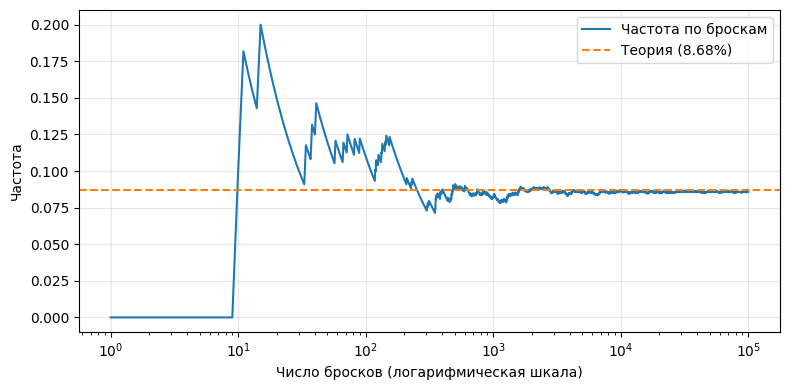

In [6]:
plt.figure(figsize=(8, 4))
plt.plot(broski, chastota, label='Частота по броскам')
plt.axhline(p, color='tab:orange', linestyle='--', label=f'Теория ({p:.2%})')
plt.xscale('log')
plt.xlabel('Число бросков (логарифмическая шкала)')
plt.ylabel('Частота')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()